# TP — RAG Multimodal et Agentique (`Attention Is All You Need`)

Implémentation complète suivant les 7 étapes du cahier des charges (`infos.md`) et l'architecture du cours (`tableau.jpg`) :

```text
PDF (PyMuPDF) ─► Textes (chunks BPE ≤ 60) + Images (PNG)
                      │
                      ▼
             CLIP ViT-B-32 (espace latent 512D normalisé L2)
                      │
                      ▼
             ChromaDB (cosine, idempotence SHA-256)
                      │
                      ▼
        Outils (@tool: retriever_tool, analyser_figure_pdf)
                      ▲
                      │  ReAct (Reasoning -> Action -> Observation)
                      ▼
        LangGraph StateGraph : MIND (LLM) ◄──► BODY (Tools)
```

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from PIL import Image

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from multimodal_rag import (
    AgenticMultimodalRAG,
    CLIPEmbedder,
    CLIPTextChunker,
    MultimodalRAGPipeline,
    MultimodalRetriever,
    MultimodalVectorStore,
    Settings,
    create_chat_model,
    extract_pdf_content,
)

settings = Settings(
    pdf_path=PROJECT_ROOT / "attention is all you need.pdf",
    output_dir=PROJECT_ROOT / "resultats_pdf",
    chroma_dir=PROJECT_ROOT / "chroma_pdf",
)
print(f"Projet : {PROJECT_ROOT}")
print(f"PDF    : {settings.pdf_path.name} (existe={settings.pdf_path.is_file()})")
print(f"LLM    : {settings.llm_provider} / {settings.gemini_model}")

C:\Users\HP\GenAI\tp_rag_multimodal_agentic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Projet : C:\Users\HP\GenAI\tp_rag_multimodal_agentic
PDF    : attention is all you need.pdf (existe=True)
LLM    : gemini / gemini-3.5-flash-lite


## Étape 1 : Extraction du contenu multimodal (Textes & Images)

Document ID (SHA-256) : d87d482d5ae7960e2e43d7dd
Pages extraites       : 11
Images extraites      : 3
Pages sans texte      : []

--- Extrait page 1 ---
             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com

        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com

                                               Illia Polosukhin∗‡
                        


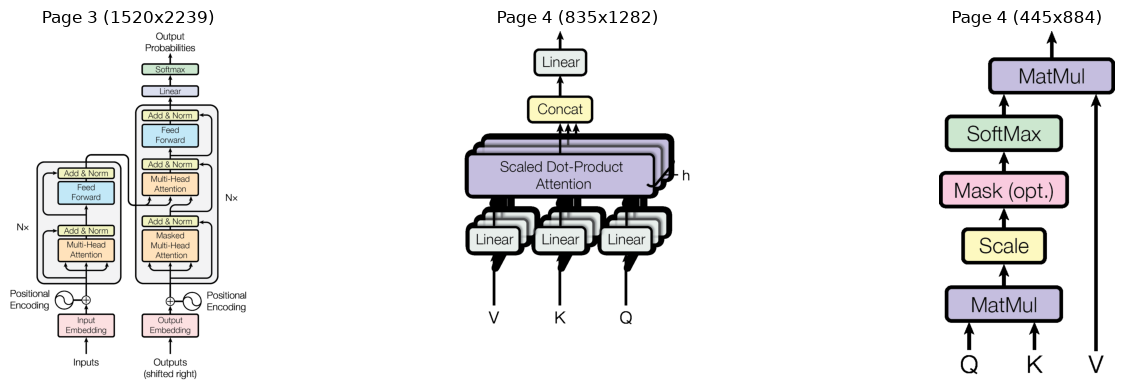

In [2]:
extraction = extract_pdf_content(settings.pdf_path, settings.output_dir)
print(f"Document ID (SHA-256) : {extraction.document_id}")
print(f"Pages extraites       : {extraction.total_pages}")
print(f"Images extraites      : {len(extraction.images)}")
print(f"Pages sans texte      : {extraction.pages_without_text}")
print("\n--- Extrait page 1 ---")
print(extraction.pages[0].text[:600])

if extraction.images:
    fig, axes = plt.subplots(1, len(extraction.images), figsize=(5 * len(extraction.images), 4))
    if len(extraction.images) == 1:
        axes = [axes]
    for ax, img_info in zip(axes, extraction.images):
        with Image.open(img_info.path) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"Page {img_info.page_number} ({img_info.width}x{img_info.height})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Étape 2 : Vectorisation dans l'espace latent commun CLIP (`ViT-B-32`)

Chaque vecteur est normalisé en norme $L_2$ ($\|v\|_2 = 1$). La matrice de similarité cosinus ci-dessous illustre l'espace latent partagé ainsi que le **CLIP Modality Gap** (les similarités intra-modales texte–texte sont naturellement plus élevées que les similarités inter-modales texte–image).

In [3]:
embedder = CLIPEmbedder(
    model_name=settings.clip_model_name,
    pretrained=settings.clip_pretrained,
)
print(f"Device : {embedder.device} | Dimension latente : {embedder.embedding_dim}")

sample_texts = [
    "Transformer encoder decoder architecture diagram",
    "Scaled Dot-Product Attention and Multi-Head Attention diagram",
    "BLEU translation scores table",
]
text_vecs = np.array(embedder.encode_texts(sample_texts))
img_vecs = np.array(embedder.encode_images([img.path for img in extraction.images]))

print("Norme L2 texte[0] :", round(float(np.linalg.norm(text_vecs[0])), 6))
print("Norme L2 image[0] :", round(float(np.linalg.norm(img_vecs[0])), 6))

sim_matrix = text_vecs @ img_vecs.T
print("\nMatrice de similarité cosinus (requêtes texte x images extraites) :")
for i, txt in enumerate(sample_texts):
    scores = [f"p.{extraction.images[j].page_number}: {sim_matrix[i, j]:.3f}" for j in range(len(extraction.images))]
    print(f"- {txt[:48]:48s} -> " + " | ".join(scores))

Device : cpu | Dimension latente : 512


Norme L2 texte[0] : 1.0
Norme L2 image[0] : 1.0

Matrice de similarité cosinus (requêtes texte x images extraites) :
- Transformer encoder decoder architecture diagram -> p.3: 0.261 | p.4: 0.256 | p.4: 0.225
- Scaled Dot-Product Attention and Multi-Head Atte -> p.3: 0.280 | p.4: 0.460 | p.4: 0.313
- BLEU translation scores table                    -> p.3: 0.144 | p.4: 0.148 | p.4: 0.166


## Étape 3 : Découpage BPE CLIP & Indexation idempotente dans ChromaDB

In [4]:
chunker = CLIPTextChunker(
    chunk_size=settings.chunk_size,
    chunk_overlap=settings.chunk_overlap,
)
store = MultimodalVectorStore(
    chroma_dir=settings.chroma_dir,
    collection_name=settings.collection_name,
    embedder=embedder,
)

report_1 = store.index_extraction(extraction, chunker, batch_size=settings.batch_size)
report_2 = store.index_extraction(extraction, chunker, batch_size=settings.batch_size)

print("Rapport 1 :", report_1.model_dump())
print("Rapport 2 (idempotence SHA-256) :", report_2.model_dump())
assert report_1.total_collection_items == report_2.total_collection_items

Rapport 1 : {'document_id': 'd87d482d5ae7960e2e43d7dd', 'pdf_name': 'attention is all you need.pdf', 'text_chunks_indexed': 216, 'images_indexed': 3, 'total_collection_items': 219}
Rapport 2 (idempotence SHA-256) : {'document_id': 'd87d482d5ae7960e2e43d7dd', 'pdf_name': 'attention is all you need.pdf', 'text_chunks_indexed': 216, 'images_indexed': 3, 'total_collection_items': 219}


## Étape 4 : Recherche multimodale (texte → texte, texte → image, image → image, hybride, FR vs EN)

In [5]:
retriever = MultimodalRetriever(store)

print("=== 1) Recherche texte (FR vs EN) ===")
for lang, q in [
    ("FR", "Pourquoi utiliser l'attention multi-têtes ?"),
    ("EN", "Why does the Transformer use multi-head attention?"),
]:
    hits = retriever.search(texte=q, type_resultat="texte", k=2)
    print(f"[{lang}] top-1 p.{hits[0].page} (sim={hits[0].similarity:.3f}) : {hits[0].content[:140]}...")

print("\n=== 2) Recherche image par texte ===")
img_hits = retriever.search(
    texte="Scaled Dot-Product Attention and Multi-Head Attention diagram",
    type_resultat="image",
    k=3,
)
for h in img_hits:
    print(f"[{h.reference}] p.{h.page} | sim={h.similarity:.3f} | {h.id}")

print("\n=== 3) Recherche par image en entrée (Figure 1 page 3) ===")
fig1_path = sorted((settings.output_dir / "images").glob("page_003_*.png"))[0]
vis_hits = retriever.search(image=fig1_path, type_resultat="hybride", k=4)
for h in vis_hits:
    print(f"[{h.reference}] {h.type.upper()} p.{h.page} | sim={h.similarity:.3f} | {h.content[:100]}")

=== 1) Recherche texte (FR vs EN) ===
[FR] top-1 p.6 (sim=0.703) : 4 Why Self-Attention...
[EN] top-1 p.5 (sim=0.748) : 3.2.3  Applications of Attention in our Model

The Transformer uses multi-head attention in three different ways:...

=== 2) Recherche image par texte ===
[S1] p.4 | sim=0.460 | d87d482d5ae7960e2e43d7dd:image:page_004_image_102.png
[S2] p.4 | sim=0.313 | d87d482d5ae7960e2e43d7dd:image:page_004_image_104.png
[S3] p.3 | sim=0.280 | d87d482d5ae7960e2e43d7dd:image:page_003_image_94.png

=== 3) Recherche par image en entrée (Figure 1 page 3) ===


[S1] TEXTE p.6 | sim=0.348 | bottoms of the encoder and decoder stacks. The positional encodings have the same dimension dmodel
a
[S2] TEXTE p.2 | sim=0.321 | End-to-end memory networks are based on a recurrent attention mechanism instead of sequence-
aligned
[S3] IMAGE p.3 | sim=1.000 | Image extraite du PDF : page_003_image_94.png (page 3)
[S4] IMAGE p.4 | sim=0.700 | Image extraite du PDF : page_004_image_104.png (page 4)


## Étapes 5 & 6 : Outils agentiques (`@tool`) & Graphe ReAct LangGraph (`MIND` ↔ `BODY`)

In [6]:
llm = create_chat_model(settings, temperature=0.0)
rag_pipeline = MultimodalRAGPipeline(
    retriever=retriever,
    llm=llm,
    max_images=settings.max_images_per_generation,
)
agent = AgenticMultimodalRAG(
    settings=settings,
    retriever=retriever,
    rag_pipeline=rag_pipeline,
    llm=llm,
)

print("Outils exposés à l'agent :")
for t in agent.tools:
    print(f"- {t.name} : {list(t.args_schema.model_fields.keys())}")

print("\nDiagramme Mermaid du graphe LangGraph :")
print(agent.get_mermaid_diagram())

Outils exposés à l'agent :
- retriever_tool : ['requete', 'type_resultat', 'k', 'chemin_image']
- analyser_figure_pdf : ['image_id', 'question']

Diagramme Mermaid du graphe LangGraph :
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	mind(mind)
	body(body)
	__end__([<p>__end__</p>]):::last
	__start__ --> mind;
	body --> mind;
	mind -.-> __end__;
	mind -.-> body;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## Étape 7 : Tests et validation de l'agent RAG multimodal

Les 3 cellules suivantes valident les 3 comportements clés de l'agent ReAct tout en restant sobres vis-à-vis des quotas API (la batterie complète à 5 scénarios E2E incluant la Figure 2 et l'attention multi-têtes est également couverte dans `tests/test_agent_e2e.py`).

In [7]:
def afficher_reponse_agent(titre: str, resp) -> None:
    display(Markdown(f"### {titre}"))
    print(f"Étapes graphe : {resp.steps_count} | Appels d'outils : {len(resp.tool_calls)}")
    for tc in resp.tool_calls:
        print("  ->", tc.name, json.dumps(tc.args, ensure_ascii=False))
    display(Markdown(resp.answer))
    if resp.images:
        for img_meta in resp.images[:2]:
            with Image.open(img_meta["chemin"]) as im:
                apercu = im.convert("RGB")
                apercu.thumbnail((450, 350))
                display(apercu)

In [8]:
r1 = agent.ask("Bonjour ! Explique brièvement ton rôle.")
afficher_reponse_agent("7.1 — Salutation sans outil (MIND -> END)", r1)

C:\Users\HP\GenAI\tp_rag_multimodal_agentic\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


### 7.1 — Salutation sans outil (MIND -> END)

Étapes graphe : 2 | Appels d'outils : 0


Bonjour ! 

Mon rôle est d'agir en tant qu'agent documentaire multimodal (basé sur une architecture ReAct) pour vous aider à explorer, analyser et exploiter les documents PDF indexés dans notre base vectorielle. 

Pour cela, je peux :
- Effectuer des recherches textuelles, visuelles ou hybrides dans le corpus pour retrouver des passages précis ou des figures ;
- Analyser en détail les schémas, graphiques et illustrations extraits des documents ;
- Répondre à vos questions scientifiques ou techniques en me basant **exclusivement** sur les informations contenues dans les documents PDF, en citant rigoureusement mes sources.

Puisque votre message ne concerne pas le contenu d'un document spécifique, je n'ai pas eu besoin de lancer de recherche. Comment puis-je vous aider aujourd'hui avec les documents indexés ?

### 7.2 — Requête multimodale hybride avec Figure 1 en entrée

Étapes graphe : 6 | Appels d'outils : 2
  -> retriever_tool {"chemin_image": "C:\\Users\\HP\\GenAI\\tp_rag_multimodal_agentic\\resultats_pdf\\images\\page_003_image_94.png", "requete": "Transformer architecture encoder decoder attention feed forward positional encoding", "k": 6, "type_resultat": "hybride"}
  -> retriever_tool {"requete": "Encoder and Decoder Stacks Attention Is All You Need section 3.1", "type_resultat": "texte", "k": 5}


À partir de l'article fondateur **« Attention Is All You Need »**, l'architecture présentée dans l'image (Figure 1 du document) correspond au modèle **Transformer**, qui adopte une structure séquentielle de type *encoder-decoder* (encodeur-décodeur) basée sur des mécanismes d'attention et des couches entièrement connectées [attention is all you need.pdf, p. 2].

Voici l'explication détaillée des différents composants illustrés :

---

### 1. Les Entrées et les Encodages Positionnels (*Inputs & Positional Encoding*)
* **Input / Output Embeddings** : Les tokens textuels d'entrée et de sortie sont convertis en vecteurs continus de dimension $d_{\text{model}}$ grâce à des couches d'embedding.
* **Positional Encoding ($\Sigma$ avec l'icône d'onde)** : Puisque le Transformer ne contient ni récurrence (RNN) ni convolutions (CNN), il n'a pas la notion intrinsèque de l'ordre des mots. Pour injecter l'information relative à la position relative ou absolue des tokens dans la séquence, des encodages positionnels (fonction sinus et cosinus de différentes fréquences) sont additionnés directement aux vecteurs d'embedding d'entrée [attention is all you need.pdf, p. 2].

---

### 2. L'Encodeur (*Encoder* - Partie Gauche)
L'encodeur est composé d'une pile de $N = 6$ couches identiques [attention is all you need.pdf, p. 2]. Chaque couche comporte deux sous-couches principales :
1. **Multi-Head Self-Attention** : Un mécanisme d'auto-attention multi-tête permettant à chaque position de l'encodeur de prêter attention à l'ensemble des positions de la couche précédente [attention is all you need.pdf, p. 2, 5].
2

. **Feed Forward (FFN)** : Un réseau de neurones fully-connected appliqué de manière indépendante et identique à chaque position, constitué de deux transformations linéaires séparées par une activation ReLU [attention is all you need.pdf, p. 5].

Chacune de ces sous-couches est entourée d'une connexion résiduelle (*residual connection*) suivie d'une normalisation de couche (*Layer Normalization*), notée **Add & Norm** [attention is all you need.pdf, p. 3].

---

### 3. Le Décodeur (*Decoder* - Partie Droite)
Le décodeur est également composé d'une pile de $N = 6$ couches identiques [attention is all you need.pdf, p. 3]. En plus des deux sous-couches de l'encodeur, il en intègre une troisième :
1. **Masked Multi-Head Self-Attention** : Une variante du mécanisme d'auto-attention masquée (*masked*). Le masque empêche les positions du décodeur de porter leur attention sur des positions futures (information "vers la gauche"), garantissant ainsi que la prédiction pour une position $i$ ne dépende que des sorties connues précédant la position $i$ [attention is all you need.pdf, p. 3, 5].
2. **Encoder-Decoder Multi-Head Attention** : Les requêtes (*queries*) proviennent de la couche précédente du décodeur, tandis que les clés (*keys*) et les valeurs (*values*) proviennent de la sortie de l'encodeur. Cela permet à chaque position du décodeur de prêter attention à toutes les positions de la séquence d'entrée (similairement aux modèles seq2seq classiques) [attention is all you need.pdf, p. 5].
3. **Feed Forward (FFN)** : Identique à celui de l'encodeur.

De même, chaque sous-couche du décodeur est protégée par un bloc **Add & Norm** (connexion résiduelle + normalisation) [attention is all you need.pdf, p. 3].

---

### 4. Les Sorties finales (*Outputs*)
* **Linear** : Une couche linéaire finale qui projette le vecteur de sortie du décodeur vers un espace de grande dimension appelé les *logits*.
* **Softmax** : Convertit les logits en probabilités prédisant le token suivant du vocabulaire (*Output Probabilities*).

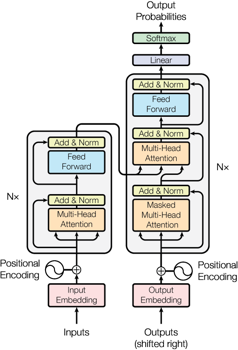

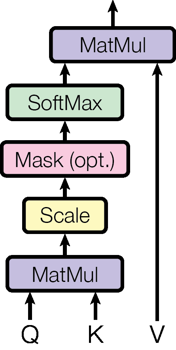

In [9]:
r2 = agent.ask(
    question="Explique les composants de cette architecture à partir de l'article Attention Is All You Need.",
    image_path=fig1_path,
    type_resultat="hybride",
    k=6,
)
afficher_reponse_agent("7.2 — Requête multimodale hybride avec Figure 1 en entrée", r2)

In [10]:
r3 = agent.ask(
    "Selon Attention Is All You Need, quel score obtient GPT-4 sur le benchmark MMLU ?",
    type_resultat="texte",
    k=6,
)
afficher_reponse_agent("7.3 — Information absente (vérification + abstention)", r3)

### 7.3 — Information absente (vérification + abstention)

Étapes graphe : 6 | Appels d'outils : 2
  -> retriever_tool {"k": 6, "requete": "GPT-4 MMLU score Attention Is All You Need", "type_resultat": "texte"}
  -> retriever_tool {"requete": "MMLU GPT-4", "k": 4, "type_resultat": "texte"}


Après vérification dans le document indexé (*Attention Is All You Need*), l'information concernant **GPT-4** et le benchmark **MMLU** n'est **pas présente** dans cet article. 

L'article fondateur *Attention Is All You Need* (Vaswani et al., 2017) a été publié bien avant l'introduction de GPT-4 (2023) et du benchmark MMLU (Massive Multitask Language Understanding, introduction en 2020), et se concentre principalement sur les tâches de traduction automatique et de modélisation linguistique (comme le montre le corpus).